In [1]:
import polars as pl
import numpy as np
import polars.selectors as sl
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sentence_transformers import SentenceTransformer, util 
from itertools import combinations
import re

pl.Config.set_fmt_str_lengths(500)
pl.Config.set_tbl_rows(-1)

polars.config.Config

In [2]:
#file_path = Path('../outputs/LLM/glint/risultati_llm_20261115_193713.csv')
file_path = Path('../outputs/LLM/cfd/risultati_llm_20261123_121217.csv')
#file_path = Path('../outputs/LLM/feret/risultati_llm_20261123_005054.csv')
df = pl.read_csv(
    file_path,
    separator=',',
    infer_schema_length=None
).drop(
    ['timestamp']
)

df.head(5)

modello,file,prompt,risposta,num_parole,tempo_s,prompt_tokens,completion_tokens
str,str,str,str,i64,f64,i64,i64
"""LFM2-1.2B""","""CFD-BF-009-006-HO.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.""","""The face shows a neutral expression with the mouth slightly open, head turned straight forward, and a clear view of the eyes. The photo captures a natural, unposed look.""",29,0.17,83,36
"""LFM2-1.2B""","""CFD-BM-011-017-HO.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.""","""The face shows a neutral expression with the mouth slightly open, head turned straight forward, and a clear view of the eyes. The photo captures a natural, unposed look.""",29,0.12,83,36
"""LFM2-1.2B""","""CFD-BM-022-027-HO.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.""","""The face shows a neutral expression with the mouth slightly open, head turned straight forward, and a clear view of the eyes. The photo captures a natural, unposed look.""",29,0.11,83,36
"""LFM2-1.2B""","""CFD-BF-029-005-HO.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.""","""The face shows a neutral expression with the mouth slightly open, head turned straight forward, and a clear view of the eyes. The photo captures a natural, unposed look.""",29,0.11,83,36
"""LFM2-1.2B""","""CFD-WF-005-027-F.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.""","""The face shows a neutral expression with the mouth slightly open, head turned straight forward, and a clear view of the eyes. The photo captures a natural, unposed look.""",29,0.11,83,36


In [3]:
models = {k[0]: v for k, v in df.partition_by('modello', as_dict=True).items()}

In [4]:
for model, m_df in models.items():
    print(f"--- {model} ---")
    display(m_df['file','risposta', 'tempo_s', 'num_parole'].head(5))

--- LFM2-1.2B ---


file,risposta,tempo_s,num_parole
str,str,f64,i64
"""CFD-BF-009-006-HO.jpg""","""The face shows a neutral expression with the mouth slightly open, head turned straight forward, and a clear view of the eyes. The photo captures a natural, unposed look.""",0.17,29
"""CFD-BM-011-017-HO.jpg""","""The face shows a neutral expression with the mouth slightly open, head turned straight forward, and a clear view of the eyes. The photo captures a natural, unposed look.""",0.12,29
"""CFD-BM-022-027-HO.jpg""","""The face shows a neutral expression with the mouth slightly open, head turned straight forward, and a clear view of the eyes. The photo captures a natural, unposed look.""",0.11,29
"""CFD-BF-029-005-HO.jpg""","""The face shows a neutral expression with the mouth slightly open, head turned straight forward, and a clear view of the eyes. The photo captures a natural, unposed look.""",0.11,29
"""CFD-WF-005-027-F.jpg""","""The face shows a neutral expression with the mouth slightly open, head turned straight forward, and a clear view of the eyes. The photo captures a natural, unposed look.""",0.11,29


--- Gemma-3-1B ---


file,risposta,tempo_s,num_parole
str,str,f64,i64
"""CFD-BF-009-006-HO.jpg""","""Here’s a description: The photograph features a head facing forward, with a slightly open mouth. The face is clearly defined and lacks any discernible expression, presenting a straightforward and neutral visual.""",0.26,31
"""CFD-BM-011-017-HO.jpg""","""The photograph depicts a person with a slightly open mouth, facing forward. The head is positioned centrally, and the face is clearly visible and free of any distracting elements.""",0.17,29
"""CFD-BM-022-027-HO.jpg""","""The photograph depicts a person with a slightly open mouth, facing forward. The head is positioned centrally, and the face is clearly visible and free of any distracting elements.""",0.17,29
"""CFD-BF-029-005-HO.jpg""","""The photograph depicts a person with a slightly open mouth, facing forward. The head is positioned centrally, and the face is clearly visible and free of any distracting elements.""",0.17,29
"""CFD-WF-005-027-F.jpg""","""The photograph depicts a person with a slightly open mouth, facing forward. The head is positioned centrally, and the face is clearly visible and free of any distracting elements.""",0.17,29


--- Qwen3-4B ---


file,risposta,tempo_s,num_parole
str,str,f64,i64
"""CFD-BF-009-006-HO.jpg""","""The subject is facing the camera with a clear, unobstructed face. The photo shows a neutral expression with a closed mouth.""",0.31,21
"""CFD-BM-011-017-HO.jpg""","""The face is centered and facing the camera. The eyes and nose are clearly visible with no obstructions.""",0.2,18
"""CFD-BM-022-027-HO.jpg""","""The face is centered and facing the camera. The eyes and nose are clearly visible with no obstructions.""",0.2,18
"""CFD-BF-029-005-HO.jpg""","""The face is centered and facing the camera. The eyes and nose are clearly visible with no obstructions.""",0.2,18
"""CFD-WF-005-027-F.jpg""","""The face is centered and facing the camera. The eyes and nose are clearly visible with no obstructions.""",0.2,18


... (4 outputs left out)

--- Qwen3-8B ---


file,risposta,tempo_s,num_parole
str,str,f64,i64
"""CFD-BF-009-006-HO.jpg""","""The passport-style face photo shows a head facing the camera with an unobstructed face. The subject has a non-neutral expression and an open mouth.""",0.53,24
"""CFD-BM-011-017-HO.jpg""","""The passport-style face photo shows a head facing the camera with an unobstructed face. The subject has a non-neutral expression and an open mouth.""",0.46,24
"""CFD-BM-022-027-HO.jpg""","""The passport-style face photo shows a head facing the camera with an unobstructed face. The subject has a non-neutral expression and an open mouth.""",0.46,24
"""CFD-BF-029-005-HO.jpg""","""The passport-style face photo shows a head facing the camera with an unobstructed face. The subject has a non-neutral expression and an open mouth.""",0.46,24
"""CFD-WF-005-027-F.jpg""","""The passport-style face photo shows a head facing the camera with an unobstructed face. The subject has a non-neutral expression and an open mouth.""",0.46,24


--- Llama-3.1-8B ---


file,risposta,tempo_s,num_parole
str,str,f64,i64
"""CFD-BF-009-006-HO.jpg""","""The passport-style face photo shows a person's head facing the camera, with their face unobstructed. However, the photo is marred by a non-neutral expression and the person's mouth is open.""",0.69,30
"""CFD-BM-011-017-HO.jpg""","""The passport-style face photo shows a person with their head facing the camera, and their face is unobstructed. However, the photo is marred by a non-neutral expression and the person's mouth is open.""",0.63,33
"""CFD-BM-022-027-HO.jpg""","""The passport-style face photo shows a person with their head facing the camera, and their face is unobstructed. However, the photo is marred by a non-neutral expression and the person's mouth is open.""",0.63,33
"""CFD-BF-029-005-HO.jpg""","""The passport-style face photo shows a person with their head facing the camera, and their face is unobstructed. However, the photo is marred by a non-neutral expression and the person's mouth is open.""",0.63,33
"""CFD-WF-005-027-F.jpg""","""The passport-style face photo shows a person with their head facing the camera, and their face is unobstructed. However, the photo is marred by a non-neutral expression and the person's mouth is open.""",0.63,33


In [5]:
target = ['num_parole', 'tempo_s', 'prompt_tokens', 'completion_tokens']

for model, df_sub in models.items():
    print(f"=== Statistiche per il modello: {model} ===")
    
    display(df_sub[target].describe())
    print("\n")

=== Statistiche per il modello: LFM2-1.2B ===


statistic,num_parole,tempo_s,prompt_tokens,completion_tokens
str,f64,f64,f64,f64
"""count""",996.0,996.0,996.0,996.0
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",24.868474,0.10998,81.701807,34.46988
"""std""",2.681365,0.008967,0.952351,3.409136
"""min""",20.0,0.08,81.0,27.0
"""25%""",25.0,0.11,81.0,36.0
"""50%""",25.0,0.11,81.0,36.0
"""75%""",25.0,0.12,83.0,36.0
"""max""",29.0,0.17,83.0,39.0




=== Statistiche per il modello: Gemma-3-1B ===


statistic,num_parole,tempo_s,prompt_tokens,completion_tokens
str,f64,f64,f64,f64
"""count""",996.0,996.0,996.0,996.0
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",25.678715,0.172811,79.050201,33.787149
"""std""",2.865001,0.019266,1.428177,3.346471
"""min""",23.0,0.15,78.0,31.0
"""25%""",23.0,0.16,78.0,31.0
"""50%""",26.0,0.17,78.0,33.0
"""75%""",28.0,0.19,81.0,38.0
"""max""",31.0,0.26,81.0,40.0




=== Statistiche per il modello: Qwen3-4B ===


statistic,num_parole,tempo_s,prompt_tokens,completion_tokens
str,f64,f64,f64,f64
"""count""",996.0,996.0,996.0,996.0
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",22.990964,0.257199,83.701807,27.860442
"""std""",1.877376,0.01701,0.952351,1.954148
"""min""",17.0,0.19,83.0,21.0
"""25%""",24.0,0.26,83.0,28.0
"""50%""",24.0,0.26,83.0,29.0
"""75%""",24.0,0.27,85.0,29.0
"""max""",24.0,0.31,85.0,30.0


... (4 outputs left out)



=== Statistiche per il modello: Qwen3-8B ===


statistic,num_parole,tempo_s,prompt_tokens,completion_tokens
str,f64,f64,f64,f64
"""count""",996.0,996.0,996.0,996.0
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",28.914659,0.548725,83.701807,37.727912
"""std""",2.30528,0.036737,0.952351,2.700691
"""min""",24.0,0.46,83.0,32.0
"""25%""",30.0,0.56,83.0,39.0
"""50%""",30.0,0.56,83.0,39.0
"""75%""",30.0,0.57,85.0,39.0
"""max""",30.0,0.6,85.0,39.0




=== Statistiche per il modello: Llama-3.1-8B ===


statistic,num_parole,tempo_s,prompt_tokens,completion_tokens
str,f64,f64,f64,f64
"""count""",996.0,996.0,996.0,996.0
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",25.900602,0.494408,105.701807,34.653614
"""std""",2.666215,0.075344,0.952351,5.071102
"""min""",24.0,0.43,105.0,31.0
"""25%""",24.0,0.44,105.0,31.0
"""50%""",24.0,0.45,105.0,31.0
"""75%""",29.0,0.58,107.0,40.0
"""max""",33.0,0.69,107.0,45.0


In [6]:
for model, m_df in models.items():
    print(f"--- {model} ---")
    display(m_df['file','prompt','risposta'].head(3))

--- LFM2-1.2B ---


file,prompt,risposta
str,str,str
"""CFD-BF-009-006-HO.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.""","""The face shows a neutral expression with the mouth slightly open, head turned straight forward, and a clear view of the eyes. The photo captures a natural, unposed look."""
"""CFD-BM-011-017-HO.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.""","""The face shows a neutral expression with the mouth slightly open, head turned straight forward, and a clear view of the eyes. The photo captures a natural, unposed look."""
"""CFD-BM-022-027-HO.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.""","""The face shows a neutral expression with the mouth slightly open, head turned straight forward, and a clear view of the eyes. The photo captures a natural, unposed look."""


--- Gemma-3-1B ---


file,prompt,risposta
str,str,str
"""CFD-BF-009-006-HO.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.""","""Here’s a description: The photograph features a head facing forward, with a slightly open mouth. The face is clearly defined and lacks any discernible expression, presenting a straightforward and neutral visual."""
"""CFD-BM-011-017-HO.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.""","""The photograph depicts a person with a slightly open mouth, facing forward. The head is positioned centrally, and the face is clearly visible and free of any distracting elements."""
"""CFD-BM-022-027-HO.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.""","""The photograph depicts a person with a slightly open mouth, facing forward. The head is positioned centrally, and the face is clearly visible and free of any distracting elements."""


--- Qwen3-4B ---


file,prompt,risposta
str,str,str
"""CFD-BF-009-006-HO.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.""","""The subject is facing the camera with a clear, unobstructed face. The photo shows a neutral expression with a closed mouth."""
"""CFD-BM-011-017-HO.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.""","""The face is centered and facing the camera. The eyes and nose are clearly visible with no obstructions."""
"""CFD-BM-022-027-HO.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.""","""The face is centered and facing the camera. The eyes and nose are clearly visible with no obstructions."""


... (4 outputs left out)

--- Qwen3-8B ---


file,prompt,risposta
str,str,str
"""CFD-BF-009-006-HO.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.""","""The passport-style face photo shows a head facing the camera with an unobstructed face. The subject has a non-neutral expression and an open mouth."""
"""CFD-BM-011-017-HO.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.""","""The passport-style face photo shows a head facing the camera with an unobstructed face. The subject has a non-neutral expression and an open mouth."""
"""CFD-BM-022-027-HO.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.""","""The passport-style face photo shows a head facing the camera with an unobstructed face. The subject has a non-neutral expression and an open mouth."""


--- Llama-3.1-8B ---


file,prompt,risposta
str,str,str
"""CFD-BF-009-006-HO.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.""","""The passport-style face photo shows a person's head facing the camera, with their face unobstructed. However, the photo is marred by a non-neutral expression and the person's mouth is open."""
"""CFD-BM-011-017-HO.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.""","""The passport-style face photo shows a person with their head facing the camera, and their face is unobstructed. However, the photo is marred by a non-neutral expression and the person's mouth is open."""
"""CFD-BM-022-027-HO.jpg""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.""","""The passport-style face photo shows a person with their head facing the camera, and their face is unobstructed. However, the photo is marred by a non-neutral expression and the person's mouth is open."""


### Confronto fra modelli: similarità fra le risposte

In [7]:
embedder_name = 'paraphrase-multilingual-MiniLM-L12-v2'
emb_model = SentenceTransformer(embedder_name)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [8]:
embeddings = {
    nome: emb_model.encode(
        d["risposta"].to_list(),  
        normalize_embeddings=True,
        batch_size=64,
        show_progress_bar=True,
    )
    for nome, d in models.items()
}

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

In [9]:
models_name = list(embeddings)

similarities = {
    (a,b): (embeddings[a] * embeddings[b]).sum(axis=1)
    for a,b in combinations(models_name,2)
}

M = np.eye(len(models_name))
for i,a in enumerate(models_name):
    for j,b in enumerate(models_name):
        if i < j:
            M[i, j] = M[j, i] = similarities[(a, b)].mean()

mat = pl.DataFrame(M,schema=models_name).with_columns(pl.Series('modello',models_name))

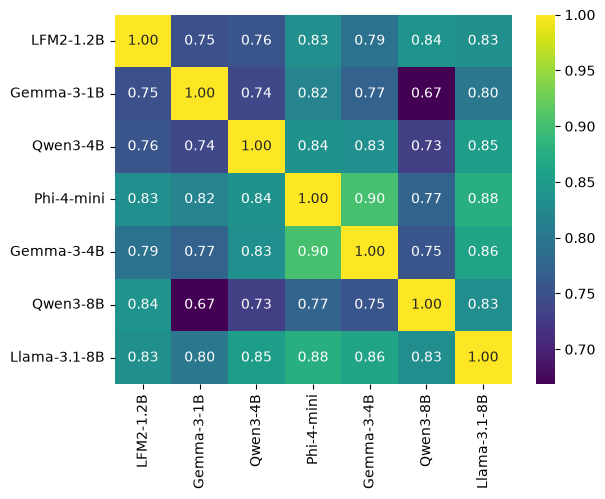

In [10]:
sns.heatmap(M, xticklabels=models_name, yticklabels=models_name, annot=True, fmt=".2f", cmap="viridis")
plt.show()

In [11]:
righe = []
for (a, b), s in similarities.items():
    righe.append({
        "A": a, "B": b,
        "media": s.mean(),
        "p5": np.percentile(s, 5),
        "mediana": np.median(s),
        "p95": np.percentile(s, 95),
    })
confronto = pl.DataFrame(righe).sort("media", descending=True)

In [12]:
confronto

A,B,media,p5,mediana,p95
str,str,f64,f64,f64,f64
"""Phi-4-mini""","""Gemma-3-4B""",0.902831,0.890671,0.894361,0.944531
"""Phi-4-mini""","""Llama-3.1-8B""",0.877867,0.865612,0.871848,0.889393
"""Gemma-3-4B""","""Llama-3.1-8B""",0.86126,0.824874,0.849024,0.937372
"""Qwen3-4B""","""Llama-3.1-8B""",0.85197,0.715628,0.892438,0.892438
"""LFM2-1.2B""","""Qwen3-8B""",0.839729,0.761134,0.878912,0.878912
"""Qwen3-4B""","""Phi-4-mini""",0.83638,0.752051,0.855905,0.883438
"""LFM2-1.2B""","""Llama-3.1-8B""",0.833653,0.771336,0.831231,0.900369
"""Qwen3-4B""","""Gemma-3-4B""",0.833006,0.765449,0.851895,0.856665
"""LFM2-1.2B""","""Phi-4-mini""",0.832219,0.798973,0.801127,0.917149


In [13]:
def get_prompt_features(p: str):
    issues, good = [], []

    m_issues = re.search(r"Issues:\s*(.*?)(?:\n|$)", p)
    m_good = re.search(r"Good aspects:\s*(.*?)(?:\n|$)", p)

    if m_issues:
        issues = [x.strip() for x in m_issues.group(1).split(";") if x.strip()]
    if m_good:
        good = [x.strip() for x in m_good.group(1).split(";") if x.strip()]

    return issues, good

In [14]:
for nome, d in list(models.items()):
    liste = [get_prompt_features(p) for p in d["prompt"].to_list()]
    models[nome] = d.with_columns(
        pl.Series("issues", [l[0] for l in liste], dtype=pl.List(pl.String)),
        pl.Series("good",   [l[1] for l in liste], dtype=pl.List(pl.String)),
    )

from transformers import pipeline

nli = pipeline("text-classification",
               model="cross-encoder/nli-deberta-v3-small", device=-1)

def valuta_modello(d, files):
    d = d.filter(pl.col("file").is_in(files))
    righe, coppie = [], []
    for r in d.iter_rows(named=True):
        for tipo, fatti in (("issue", r["issues"]), ("good", r["good"])):
            for f in fatti:
                righe.append((r["file"], tipo, f))
                coppie.append({"text": r["risposta"],
                               "text_pair": f"The photo shows {f}."})
    out = nli(coppie, batch_size=32, truncation=True)
    return pl.DataFrame({
        "file":  [x[0] for x in righe],
        "tipo":  [x[1] for x in righe],
        "fatto": [x[2] for x in righe],
        "label": [o["label"].lower() for o in out],
    })

files = df["file"].unique(maintain_order=True).sample(300, seed=0).to_list()
risultati = {nome: valuta_modello(d, files) for nome, d in models.items()}

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

In [15]:
tab = []
for nome, r in risultati.items():
    iss = r.filter(pl.col("tipo") == "issue")
    tab.append({
        "modello": nome,
        "recall_difetti": (iss["label"] == "entailment").mean(),
        "difetti_omessi": (iss["label"] == "neutral").mean(),
        "contraddizioni": (r["label"] == "contradiction").mean(),
    })
pl.DataFrame(tab).sort("recall_difetti", descending=True)

r = risultati["Phi-4-mini"]
r.filter((pl.col("tipo") == "issue") & (pl.col("label") != "entailment")).sample(20, seed=1)

file,tipo,fatto,label
str,str,str,str
"""CFD-BF-202-109-N.jpg""","""issue""","""none.""","""contradiction"""
"""CFD-IM-738-191-N.jpg""","""issue""","""none.""","""contradiction"""
"""CFD-LM-214-165-N.jpg""","""issue""","""none.""","""contradiction"""
"""CFD-BF-212-315-N.jpg""","""issue""","""none.""","""contradiction"""
"""CFD-IM-719-221-N.jpg""","""issue""","""none.""","""contradiction"""
"""CFD-BM-242-233-N.jpg""","""issue""","""none.""","""contradiction"""
"""CFD-AM-226-234-N.jpg""","""issue""","""none.""","""contradiction"""
"""CFD-MF-345-025-N.jpg""","""issue""","""none.""","""contradiction"""
"""CFD-BF-021-013-N.jpg""","""issue""","""none.""","""contradiction"""


In [16]:
lungo = pl.concat([
    r.select("file", "tipo", "fatto", "label")
     .with_columns(modello=pl.lit(nome))
    for nome, r in risultati.items()
]).with_columns(
    contraddizione=(pl.col("label") == "contradiction")
)

tabella = (
    lungo.pivot(
        on="modello",
        index=["tipo", "file", "fatto"],
        values="contraddizione",
        aggregate_function="first",
    )
    .sort("tipo", "file")
)
tabella.head(10)

tipo,file,fatto,LFM2-1.2B,Gemma-3-1B,Qwen3-4B,Phi-4-mini,Gemma-3-4B,Qwen3-8B,Llama-3.1-8B
str,str,str,bool,bool,bool,bool,bool,bool,bool
"""good""","""CFD-AF-211-066-N.jpg""","""neutral expression.""",false,false,false,false,false,false,false
"""good""","""CFD-AF-211-066-N.jpg""","""face unobstructed""",false,false,false,false,false,false,false
"""good""","""CFD-AF-211-066-N.jpg""","""head facing the camera""",false,false,false,false,false,false,false
"""good""","""CFD-AF-215-70-N.jpg""","""neutral expression.""",false,false,false,false,false,false,false
"""good""","""CFD-AF-215-70-N.jpg""","""face unobstructed""",false,false,false,false,false,false,false
"""good""","""CFD-AF-215-70-N.jpg""","""head facing the camera""",false,false,false,false,false,false,false
"""good""","""CFD-AF-216-106-N.jpg""","""head facing the camera""",false,false,false,false,false,false,false
"""good""","""CFD-AF-216-106-N.jpg""","""neutral expression.""",false,false,false,false,false,false,false
"""good""","""CFD-AF-216-106-N.jpg""","""face unobstructed""",false,false,false,false,false,false,false


In [17]:
# lungo = pl.concat([
#     r.with_columns(modello=pl.lit(nome))
#     for nome, r in risultati.items()
# ])

# # 2) aggiungi la risposta del LLM, altrimenti non puoi annotare
# risposte = pl.concat([
#     d.select("file", "risposta").with_columns(modello=pl.lit(nome))
#     for nome, d in models.items()
# ])
# lungo = lungo.join(risposte, on=["modello", "file"], how="left")

# # 3) campione stratificato per (tipo, label): max 17 righe per gruppo -> circa 100
# campione = (
#     lungo.group_by("tipo", "label", maintain_order=True)
#          .map_groups(lambda g: g.sample(min(17, g.height), seed=0))
#          .select("modello", "file", "tipo", "fatto", "risposta", "label")
#          .with_columns(label_umana=pl.lit(None, dtype=pl.String))
# )
# campione.write_csv("../outputs/validazione_nli.csv")
# print(campione.height)

In [18]:
tabella = pl.DataFrame(tab).sort("recall_difetti", descending=True)
tabella

modello,recall_difetti,difetti_omessi,contraddizioni
str,f64,f64,f64
"""Gemma-3-4B""",1.0,0.0,0.0
"""Llama-3.1-8B""",1.0,0.0,0.0
"""Qwen3-8B""",0.431429,0.0,0.165833
"""Phi-4-mini""",0.425714,0.0,0.169167
"""Gemma-3-1B""",0.38,0.0,0.220833
"""Qwen3-4B""",0.291429,0.002857,0.220833
"""LFM2-1.2B""",0.151429,0.0,0.2475


### Controllo per ogni modello delle feature giuste e sbagliate in base al prompt

In [19]:
tab = []

for nome, r in risultati.items():
    issues = r.filter(pl.col("tipo") == "issue")
    good = r.filter(pl.col("tipo") == "good")

    tab.append({
        "modello": nome,
        "recall_difetti": (issues["label"] == "entailment").mean(),
        "recall_aspetti_positivi": (good["label"] == "entailment").mean(),
        "fatti_contraddetti": (r["label"] == "contradiction").mean(),
        "fatti_non_citati": (r["label"] == "neutral").mean()
    })

pl.DataFrame(tab).sort("recall_difetti", descending=True)

modello,recall_difetti,recall_aspetti_positivi,fatti_contraddetti,fatti_non_citati
str,f64,f64,f64,f64
"""Gemma-3-4B""",1.0,1.0,0.0,0.0
"""Llama-3.1-8B""",1.0,1.0,0.0,0.0
"""Qwen3-8B""",0.431429,1.0,0.165833,0.0
"""Phi-4-mini""",0.425714,0.997647,0.169167,0.0
"""Gemma-3-1B""",0.38,0.943529,0.220833,0.0
"""Qwen3-4B""",0.291429,0.978824,0.220833,0.000833
"""LFM2-1.2B""",0.151429,1.0,0.2475,0.0


In [35]:
import base64, html, io
from pathlib import Path

import polars as pl
from PIL import Image
from IPython.display import HTML, display


def mostra_tabella(df, shards_dir, cols=None, n=5, files=None, seed=0, width=110, file_col="file"):
    index = {p.name: p for p in Path(shards_dir).expanduser().glob("shard_*/*")
             if p.suffix.lower() in {".png", ".jpg", ".jpeg", ".ppm"}}

    if files is None:
        tutti = df[file_col].unique(maintain_order=True)
        files = tutti.sample(min(n, len(tutti)), seed=seed).to_list()
    cols = cols or [c for c in df.columns if c not in file_col]
    sub = {r[file_col]: r for r in df.filter(pl.col(file_col).is_in(files)).iter_rows(named=True)}

    def miniatura(name):
        if name not in index:
            return "<i>immagine non trovata</i>"
        im = Image.open(index[name]).convert("RGB")
        im.thumbnail((width * 2, width * 3))
        buf = io.BytesIO()
        im.save(buf, "JPEG", quality=80)
        return f'<img src="data:image/jpeg;base64,{base64.b64encode(buf.getvalue()).decode()}" width="{width}">'

    def testo(v):
        if v is None:
            return "-"
        return html.escape("; ".join(map(str, v)) if isinstance(v, list) else str(v))

    righe = []
    for f in files:
        r = sub.get(f, {})
        nome = Path(f).name
        celle = [f"<td>{miniatura(nome)}<br><small>{html.escape(nome)}</small></td>"]
        celle += [f"<td>{testo(r.get(c))}</td>" for c in cols]
        righe.append("<tr>" + "".join(celle) + "</tr>")

    css = ("<style>.tm{border-collapse:collapse;font-size:13px}.tm td,.tm th{border:1px solid #ccc;"
           "padding:6px;vertical-align:top;max-width:260px;word-wrap:break-word;text-align:left}"
           ".tm th{background:#f2f2f2}</style>")
    intest = "".join(f"<th>{html.escape(str(c))}</th>" for c in cols)
    display(HTML(f"{css}<table class='tm'><tr><th>immagine</th>{intest}</tr>" + "".join(righe) + "</table>"))

immagine,modello,prompt,risposta,num_parole,tempo_s,prompt_tokens,completion_tokens
CFD-BF-007-013-A.jpg,LFM2-1.2B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression. Good aspects: head facing the camera; face unobstructed; mouth closed.","The face shows a neutral expression with the head turned toward the camera, an unobstructed face, and a mouth closed.",20,0.09,83,27
CFD-BM-025-051-F.jpg,LFM2-1.2B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.","The face shows a neutral expression with the mouth slightly open, head turned straight forward, and a clear view of the eyes. The photo captures a natural, unposed look.",29,0.12,83,36
CFD-IF-729-393-N.jpg,LFM2-1.2B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: none. Good aspects: head facing the camera; face unobstructed; neutral expression.","The photo features a person with a straightforward, neutral expression, facing the camera directly with an unobstructed face. The image captures a clear, passport-style profile.",25,0.11,81,36
CFD-BF-004-009-HO.jpg,LFM2-1.2B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.","The face shows a neutral expression with the mouth slightly open, head turned straight forward, and a clear view of the eyes. The photo captures a natural, unposed look.",29,0.12,83,36
CFD-LM-215-247-N.jpg,LFM2-1.2B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: none. Good aspects: head facing the camera; face unobstructed; neutral expression.","The photo features a person with a straightforward, neutral expression, facing the camera directly with an unobstructed face. The image captures a clear, passport-style profile.",25,0.11,81,36
CFD-BM-028-028-HO.jpg,LFM2-1.2B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.","The face shows a neutral expression with the mouth slightly open, head turned straight forward, and a clear view of the eyes. The photo captures a natural, unposed look.",29,0.12,83,36
CFD-BF-002-004-HO.jpg,LFM2-1.2B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.","The face shows a neutral expression with the mouth slightly open, head turned straight forward, and a clear view of the eyes. The photo captures a natural, unposed look.",29,0.12,83,36
CFD-BM-040-013-A.jpg,LFM2-1.2B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral exp
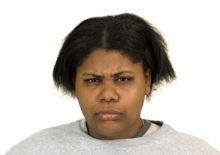
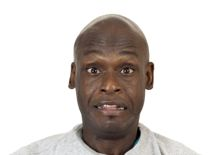
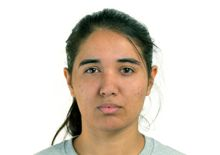
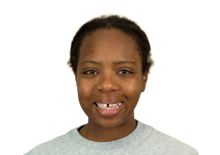
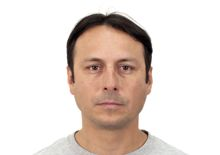
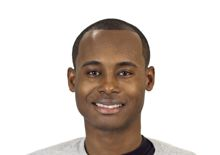
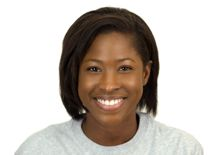
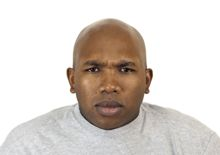
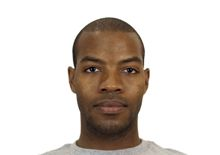
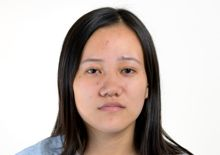

immagine,modello,prompt,risposta,num_parole,tempo_s,prompt_tokens,completion_tokens
CFD-BF-007-013-A.jpg,Qwen3-8B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression. Good aspects: head facing the camera; face unobstructed; mouth closed.","The passport-style face photo shows a head facing the camera with an unobstructed face and a closed mouth. The expression is non-neutral, but the overall composition meets the required criteria.",30,0.57,85,39
CFD-BM-025-051-F.jpg,Qwen3-8B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.",The passport-style face photo shows a head facing the camera with an unobstructed face. The subject has a non-neutral expression and an open mouth.,24,0.48,85,32
CFD-IF-729-393-N.jpg,Qwen3-8B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: none. Good aspects: head facing the camera; face unobstructed; neutral expression.","The passport-style face photo shows a clear, unobstructed view of the face with the head directly facing the camera. The expression is neutral, meeting the required standards for identification purposes.",30,0.56,83,39
CFD-BF-004-009-HO.jpg,Qwen3-8B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.",The passport-style face photo shows a head facing the camera with an unobstructed face. The subject has a non-neutral expression and an open mouth.,24,0.49,85,32
CFD-LM-215-247-N.jpg,Qwen3-8B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: none. Good aspects: head facing the camera; face unobstructed; neutral expression.","The passport-style face photo shows a clear, unobstructed view of the face with the head directly facing the camera. The expression is neutral, meeting the required standards for identification purposes.",30,0.56,83,39
CFD-BM-028-028-HO.jpg,Qwen3-8B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.",The passport-style face photo shows a head facing the camera with an unobstructed face. The subject has a non-neutral expression and an open mouth.,24,0.48,85,32
CFD-BF-002-004-HO.jpg,Qwen3-8B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.",The passport-style face photo shows a head facing the camera with an unobstructed face. The subject has a non-neutral expression and an open mouth.,24,0.49,85,32
CFD-BM-040-013-A.jpg,Qwen3-8B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not liste
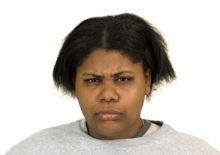
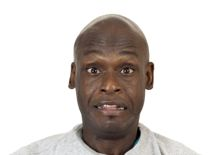
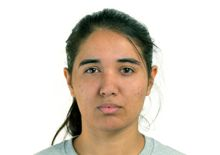
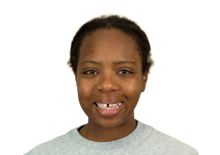
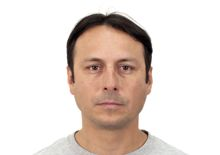
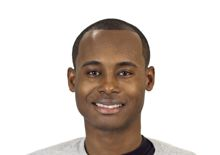
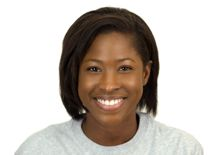
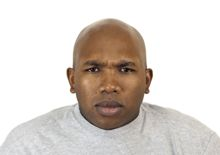
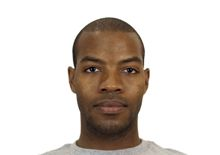
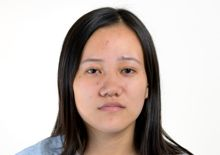

immagine,modello,prompt,risposta,num_parole,tempo_s,prompt_tokens,completion_tokens
CFD-BF-007-013-A.jpg,Gemma-3-1B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression. Good aspects: head facing the camera; face unobstructed; mouth closed.","The photograph depicts a person with a closed mouth and a neutral expression, facing the camera directly. The head is positioned prominently, creating a focused and straightforward visual.",28,0.17,81,33
CFD-BM-025-051-F.jpg,Gemma-3-1B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.","The photograph depicts a person with a slightly open mouth, facing forward. The head is positioned centrally, and the face is clearly visible and free of any distracting elements.",29,0.17,81,34
CFD-IF-729-393-N.jpg,Gemma-3-1B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: none. Good aspects: head facing the camera; face unobstructed; neutral expression.","The image features a person with a centered, slightly upward-facing head. Their face is presented in a straightforward, calm manner, with minimal distractions.",23,0.16,78,31
CFD-BF-004-009-HO.jpg,Gemma-3-1B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.","Here’s a description: The photograph features a head facing forward, with a slightly open mouth. The face is clearly defined and lacks any discernible expression, presenting a straightforward and neutral visual.",31,0.21,81,40
CFD-LM-215-247-N.jpg,Gemma-3-1B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: none. Good aspects: head facing the camera; face unobstructed; neutral expression.","The image features a person with a centered, slightly upward-facing head. Their face is presented in a straightforward, calm manner, with minimal distractions.",23,0.15,78,31
CFD-BM-028-028-HO.jpg,Gemma-3-1B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.","Here’s a description: The photograph features a head facing forward, with a slightly open mouth. The face is clearly defined and lacks any discernible expression, presenting a straightforward and neutral visual.",31,0.21,81,40
CFD-BF-002-004-HO.jpg,Gemma-3-1B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.","The photograph depicts a person with a slightly open mouth, facing forward. The head is positioned centrally, and the face is clearly visible and free of any distracting elements.",29,0.17,81,34
CFD-BM-040-013-A.jpg,Gemma-3-1B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONL
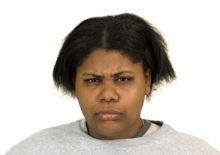
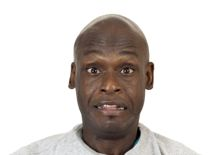
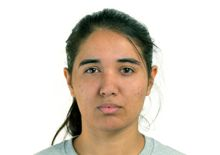
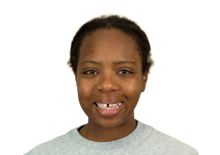
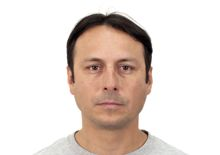
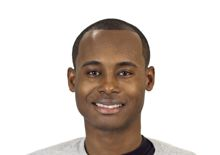
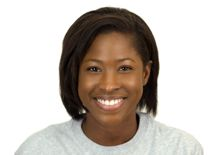
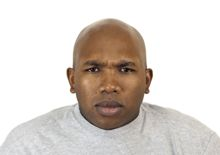
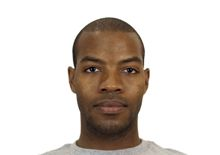
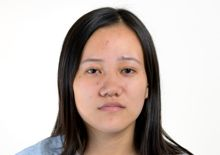

immagine,modello,prompt,risposta,num_parole,tempo_s,prompt_tokens,completion_tokens
CFD-BF-007-013-A.jpg,Qwen3-4B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression. Good aspects: head facing the camera; face unobstructed; mouth closed.","The subject is facing the camera with their face fully visible and their mouth closed. The expression is neutral, with no visible emotional cues.",24,0.27,85,28
CFD-BM-025-051-F.jpg,Qwen3-4B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.","The face is centered and facing the camera. The eyes are open, and the face is fully visible without obstructions.",20,0.25,85,25
CFD-IF-729-393-N.jpg,Qwen3-4B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: none. Good aspects: head facing the camera; face unobstructed; neutral expression.","The subject's head is facing the camera directly. The face is fully visible with a neutral expression, showing no signs of obstruction or distortion.",24,0.26,83,29
CFD-BF-004-009-HO.jpg,Qwen3-4B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.","The face is centered and facing the camera. The eyes are open, and the face is fully visible without obstructions.",20,0.26,85,25
CFD-LM-215-247-N.jpg,Qwen3-4B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: none. Good aspects: head facing the camera; face unobstructed; neutral expression.","The subject's head is facing the camera directly. The face is fully visible with a neutral expression, showing no signs of obstruction or distortion.",24,0.26,83,29
CFD-BM-028-028-HO.jpg,Qwen3-4B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.","The face is centered and facing the camera. The eyes are open, and the face is fully visible without obstructions.",20,0.25,85,25
CFD-BF-002-004-HO.jpg,Qwen3-4B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.","The face is centered and facing the camera. The eyes are open, and the face is fully visible without obstructions.",20,0.24,85,25
CFD-BM-040-013-A.jpg,Qwen3-4B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression. Good aspects: head facing the camera; face unobstructed; mouth closed.","The subject is facing the camera with their face fully visible and their mouth closed. The expression is neutral, with no visible emotional cues.",24,0.27,85,28
CFD-BM-002-01
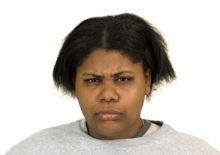
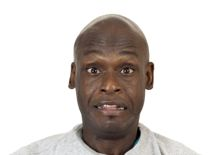
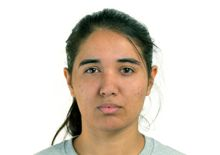
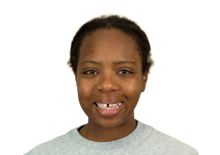
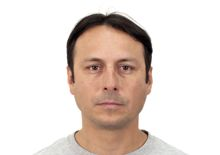
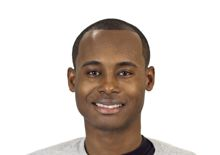
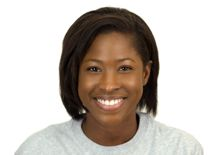
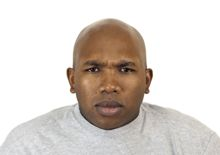
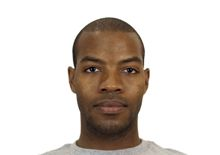
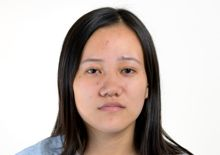

immagine,modello,prompt,risposta,num_parole,tempo_s,prompt_tokens,completion_tokens
CFD-BF-007-013-A.jpg,Llama-3.1-8B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression. Good aspects: head facing the camera; face unobstructed; mouth closed.","The photo shows a person's face, head facing the camera, with their mouth closed and unobstructed by any objects. The expression is non-neutral, but the face is clearly visible.",29,0.57,107,40
CFD-BM-025-051-F.jpg,Llama-3.1-8B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.","The passport-style face photo shows a person's head facing the camera, with their face unobstructed. However, the photo is marred by a non-neutral expression and the person's mouth is open.",30,0.62,107,43
CFD-IF-729-393-N.jpg,Llama-3.1-8B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: none. Good aspects: head facing the camera; face unobstructed; neutral expression.","The photo shows a person's face directly facing the camera, with no obstructions or distractions. The face is clearly visible, with a neutral expression.",24,0.43,105,31
CFD-BF-004-009-HO.jpg,Llama-3.1-8B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.","The passport-style face photo shows a person's head facing the camera, with their face unobstructed. However, the photo is marred by a non-neutral expression and the person's mouth is open.",30,0.62,107,43
CFD-LM-215-247-N.jpg,Llama-3.1-8B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: none. Good aspects: head facing the camera; face unobstructed; neutral expression.","The photo shows a person's face directly facing the camera, with no obstructions or distractions. The face is clearly visible, with a neutral expression.",24,0.44,105,31
CFD-BM-028-028-HO.jpg,Llama-3.1-8B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.","The passport-style face photo shows a person's head facing the camera, with their face unobstructed. However, the photo is marred by a non-neutral expression and the person's mouth is open.",30,0.62,107,43
CFD-BF-002-004-HO.jpg,Llama-3.1-8B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.","The passport-style face photo shows a person's head facing the camera, with their face unobstructed. However, the photo is marred by a non-neutral expression and the person's mouth is open.",30,0.62,107,43
CFD-BM-040-013-A.jpg,Llama-3.1-8B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do no
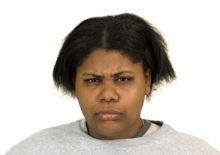
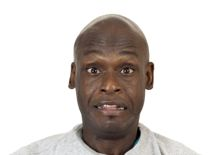
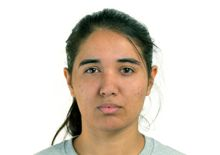
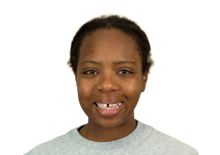
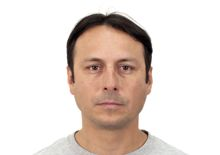
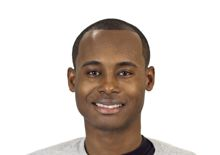
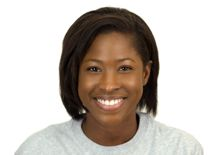
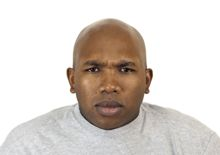
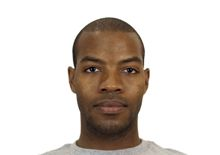
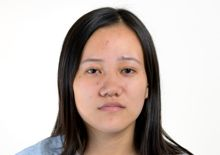

immagine,modello,prompt,risposta,num_parole,tempo_s,prompt_tokens,completion_tokens
CFD-BF-007-013-A.jpg,Phi-4-mini,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression. Good aspects: head facing the camera; face unobstructed; mouth closed.","The photo shows a head facing directly towards the camera with a clear, unobstructed view of the face and a closed mouth.",22,0.24,74,27
CFD-BM-025-051-F.jpg,Phi-4-mini,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.","The face photo shows a head facing the camera with an open mouth, ensuring the face is unobstructed. However, the expression is non-neutral.",23,0.27,74,31
CFD-IF-729-393-N.jpg,Phi-4-mini,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: none. Good aspects: head facing the camera; face unobstructed; neutral expression.","The photo shows a head facing directly towards the camera with a clear, unobstructed view of the face and a neutral expression.",22,0.23,72,27
CFD-BF-004-009-HO.jpg,Phi-4-mini,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.","The face photo shows a head facing the camera with an open mouth, ensuring the face is unobstructed. However, the expression is non-neutral.",23,0.28,74,31
CFD-LM-215-247-N.jpg,Phi-4-mini,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: none. Good aspects: head facing the camera; face unobstructed; neutral expression.","The photo shows a head facing directly towards the camera with a clear, unobstructed view of the face and a neutral expression.",22,0.23,72,27
CFD-BM-028-028-HO.jpg,Phi-4-mini,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.","The face photo shows a head facing the camera with an open mouth, ensuring the face is unobstructed. However, the expression is non-neutral.",23,0.28,74,31
CFD-BF-002-004-HO.jpg,Phi-4-mini,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.","The face photo shows a head facing the camera with an open mouth, ensuring the face is unobstructed. However, the expression is non-neutral.",23,0.27,74,31
CFD-BM-040-013-A.jpg,Phi-4-mini,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression. Good aspects: head facing the camera; face unobstructed; mouth closed.","The photo shows a head facing directly towards the camera with a clear, unobstructed view of the face and a closed mouth."
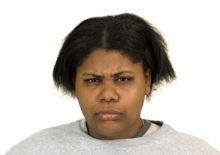
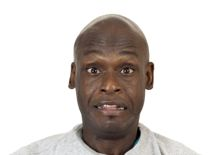
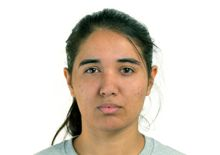
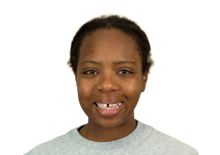
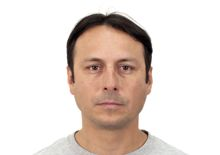
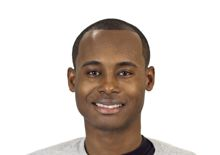
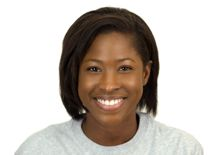
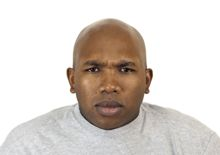
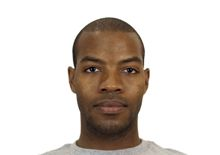
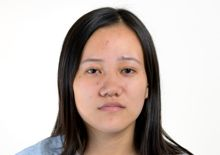

immagine,modello,prompt,risposta,num_parole,tempo_s,prompt_tokens,completion_tokens
CFD-BF-007-013-A.jpg,Gemma-3-4B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression. Good aspects: head facing the camera; face unobstructed; mouth closed.","The photograph presents a face, head-on to the camera, with an unobstructed view. The expression is non-neutral, and the mouth is closed.",22,0.34,81,32
CFD-BM-025-051-F.jpg,Gemma-3-4B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.","The photograph presents a face, head-on to the camera, with an unobstructed view. A non-neutral expression is noted, accompanied by an open mouth.",23,0.34,81,33
CFD-IF-729-393-N.jpg,Gemma-3-4B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: none. Good aspects: head facing the camera; face unobstructed; neutral expression.","The photograph presents a head facing the camera with an unobstructed face. A neutral expression is observed, indicating no particular emotion.",21,0.25,78,25
CFD-BF-004-009-HO.jpg,Gemma-3-4B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.","The photograph presents a face, head-on to the camera, with an unobstructed view. A non-neutral expression is noted, accompanied by an open mouth.",23,0.34,81,33
CFD-LM-215-247-N.jpg,Gemma-3-4B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: none. Good aspects: head facing the camera; face unobstructed; neutral expression.","The photograph presents a head facing the camera with an unobstructed face. A neutral expression is observed, indicating no particular emotion.",21,0.26,78,25
CFD-BM-028-028-HO.jpg,Gemma-3-4B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.","The photograph presents a face, head-on to the camera, with an unobstructed view. A non-neutral expression is noted, accompanied by an open mouth.",23,0.35,81,33
CFD-BF-002-004-HO.jpg,Gemma-3-4B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression; mouth open. Good aspects: head facing the camera; face unobstructed.","The photograph presents a face, head-on to the camera, with an unobstructed view. A non-neutral expression is noted, accompanied by an open mouth.",23,0.34,81,33
CFD-BM-040-013-A.jpg,Gemma-3-4B,"Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed.Issues: non-neutral expression. Good aspects: head facing the camera; face unobstructed; mouth closed.","The photograph presents a face, head-on to the cam
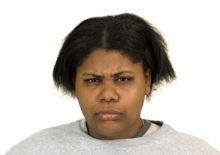
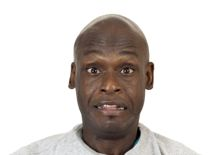
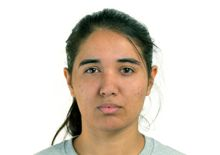
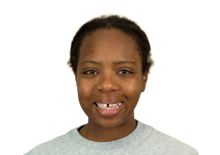
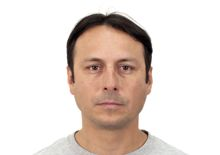
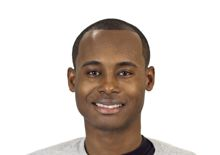
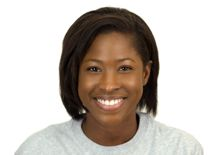
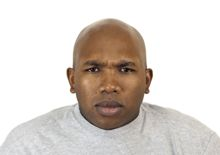
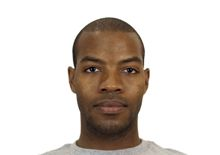
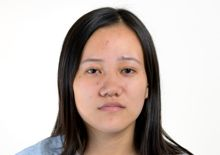

In [36]:
for m in df.select('modello').unique().iter_rows():
    x, = m
    mostra_tabella(df.filter(pl.col('modello') == x), "~/prove/cfd_all/images", n=10)    